# Drive a Scenario

This notebook demonstrates how to use the "Driver" module in OTTER.

- use a seeded world scenario
- use a route and a driver
- CARLA simulation
- record drive telemetry
- evaluate telemetry against STL sepcifications


In [1]:
from pathlib import Path

from pyotter import Driver, Planner, Visualize, World
from pyotter.core import DrivingSafetyReq, WorldHazardLibrary, WorldRoadGraph
from pyotter.modules.driver import DriverModel, DrivingScenarioTelemetry
from pyotter.modules.planner import PlannerConfig

OUTPUT = Path("runs")
OUTPUT.mkdir(exist_ok=True)

## (Example) Running three drives in the same world seed

The forecast comes from `world_demo.ipynb`, and the trip comes from `planner_demo.ipynb`. 

One seed rolls the hazards, so all three drivers interact with the same deterministic world. This allows us to compare the telemetry of each drive.

In [2]:
hazards = WorldHazardLibrary()
wrg = WorldRoadGraph.from_template("town10")
for lane in wrg.segments_in_junction(189):
    lane.assign_hazard_probability([(hazards.pedestrian, 0.03)])
for lane in wrg.segments_in_junction(841):
    lane.assign_hazard_probability([(hazards.pedestrian, 0.01)])
wrg.set_condition(hazards.wet_road, probability=0.9, severity="high", variability=0.1)
wrg.set_condition(hazards.low_visibility, probability=0.5, severity="mid", variability=0.4)
wrg.set_time_of_day(17.5)

SEED = 1227
spawns = World.roll_hazards(wrg, hazards, seed=SEED, duration_s=150)

A, B = wrg.spawn_points[18], wrg.spawn_points[127]
config = PlannerConfig(weights={"pedestrian": 20.0})
routes = {mode: Planner.route(A, B, wrg, mode=mode, risk_scale=2, config=config)
          for mode in ("naive", "cautious", "risk-aware")}

for condition in spawns.conditions:
    print(f"{condition.hazard_id}: severity {condition.severity:.2f} ({condition.level})")
print(f"sun: facing it loses {spawns.sun.strength:.2f}")
print(f"{len(spawns.events)} pedestrian starts in {spawns.duration_s:g} s")

low_visibility: severity 0.42 (mid)
wet_road: severity 0.87 (high)
sun: facing it loses 0.49
100 pedestrian starts in 150 s


## The Driver Model

The safety requirements are the limits a drive must stay within. The driver always behaves to stay within these requirements. Through telemetry evaluation, we measure any policy violations and the margin to policy adherence to get an overal "safety" score per run.

The driver model works with these environmentally-dependent factors:
- visibility - how far ahead it notices another road user in clear conditions
- braking power - the maximum braking force allowed either by policy or road conditions

In [3]:
safety = DrivingSafetyReq(min_gap_m=2.0, max_deceleration_mps2=6.0, max_acceleration_mps2=3.0, speed_tolerance_kmh=3.0)
driver = DriverModel(safety=safety, detection_range_m=60.0, comfortable_deceleration_mps2=3.0)

wet, fog = spawns.condition_severity(hazards.wet_road), spawns.condition_severity(hazards.low_visibility)
print(f"sight in this run's rain or fog:  {driver.detection_range(fog):.0f} m of {driver.detection_range_m:g} m")
print(f"sight when also facing the sun:   {driver.detection_range(min(1.0, fog + spawns.sun.strength)):.0f} m")
print(f"braking planned on this wet road: {driver.planned_deceleration(wet):.1f} of {driver.comfortable_deceleration_mps2:g} m/s2")

sight in this run's rain or fog:  35 m of 60 m
sight when also facing the sun:   5 m
braking planned on this wet road: 1.7 of 3 m/s2


## Scenario Files

Everything a run needs is stored in one scenario file. The file contains the road graph, seeded hazards, the route, and the driver model.

In [4]:
for mode, route in routes.items():
    scenario = Driver.scenario(wrg, spawns, route, driver=driver, name=f"town10-seed{SEED}-{mode}")
    path = OUTPUT / f"{scenario.name}.json.gz"
    scenario.save(path)
    print(f"{path}  {route.estimated_time_s:5.1f} s planned, {path.stat().st_size / 1024:.0f} KB")

runs/town10-seed1227-naive.json.gz   59.7 s planned, 100 KB
runs/town10-seed1227-cautious.json.gz   89.6 s planned, 100 KB
runs/town10-seed1227-risk-aware.json.gz   72.1 s planned, 100 KB


## Running a scenario in CARLA

Run a scenario on a running CARLA 0.9.16 server:

```bash
python -m pyotter drive runs/town10-seed1227-naive.json.gz
```

`use-pyotter/carla/README.md` has the launch scripts that start a server, drive, and stop it, for CARC Discovery, for macOS with the Wine wrapper, and for Docker. 

On the Mac, from the repo root:

```bash
use-pyotter/carla/wine/server start
use-pyotter/carla/wine/pyotter drive use-pyotter/runs/town10-seed1227-*.json.gz
use-pyotter/carla/wine/server stop
```

The rest of this notebook uses an existing the telemetry files from `runs/` (.gitignored)

In [5]:
runs = {}
for mode in routes:
    path = OUTPUT / f"town10-seed{SEED}-{mode}-telemetry.json.gz"
    if path.exists():
        runs[mode] = DrivingScenarioTelemetry.load(path)
        run = runs[mode]
        print(f"{mode:11} {run.outcome}, {run.duration_s:5.1f} s, {run.distance_m:.0f} m, {len(run)} samples, "
              f"{len(run.events_of('hazard_started'))} pedestrians started, {len(run.events_of('collision'))} collisions")
    else:
        print(f"{mode:11} no telemetry yet: drive {path.name.replace('-telemetry', '')} first")

naive       arrived,  63.3 s, 496 m, 1266 samples, 50 pedestrians started, 0 collisions
cautious    arrived, 103.1 s, 496 m, 2062 samples, 69 pedestrians started, 2 collisions
risk-aware  arrived,  74.4 s, 501 m, 1488 samples, 59 pedestrians started, 0 collisions


## Telemetry

Telemetry is a set of signals sampled once per tick, with a list of events. `gap_m` is the distance from the car's body to the nearest other road user.

In [6]:
if runs:
    run = next(iter(runs.values()))
    print("signals:", ", ".join(run.signals))
    print("conditions:", {name: round(value, 2) for name, value in run.conditions.items()})
    print("first events:")
    for event in run.events[:4]:
        print(f"  {event.time_s:6.2f} s  {event.kind}  {event.detail}")

signals: acceleration_mps2, allowed_speed_mps, brake, collision, detection_range_m, gap_ahead_m, gap_m, progress_m, remaining_m, speed_limit_mps, speed_mps, steer, target_speed_mps, throttle, time_s, x, y, yaw_deg, z
conditions: {'low_visibility': 0.42, 'sun_glare': 0.49, 'wet_road': 0.87}
first events:
    2.95 s  hazard_started  {'hazard_id': 'pedestrian', 'offset_m': 36.8, 'segment_id': 'r467.s0.l-1'}
    4.50 s  hazard_started  {'hazard_id': 'pedestrian', 'offset_m': 22.41, 'segment_id': 'r268.s0.l-1'}
    4.55 s  hazard_started  {'hazard_id': 'pedestrian', 'offset_m': 39.2, 'segment_id': 'r315.s0.l-1'}
    4.60 s  hazard_started  {'hazard_id': 'pedestrian', 'offset_m': 12.36, 'segment_id': 'r395.s0.l1'}


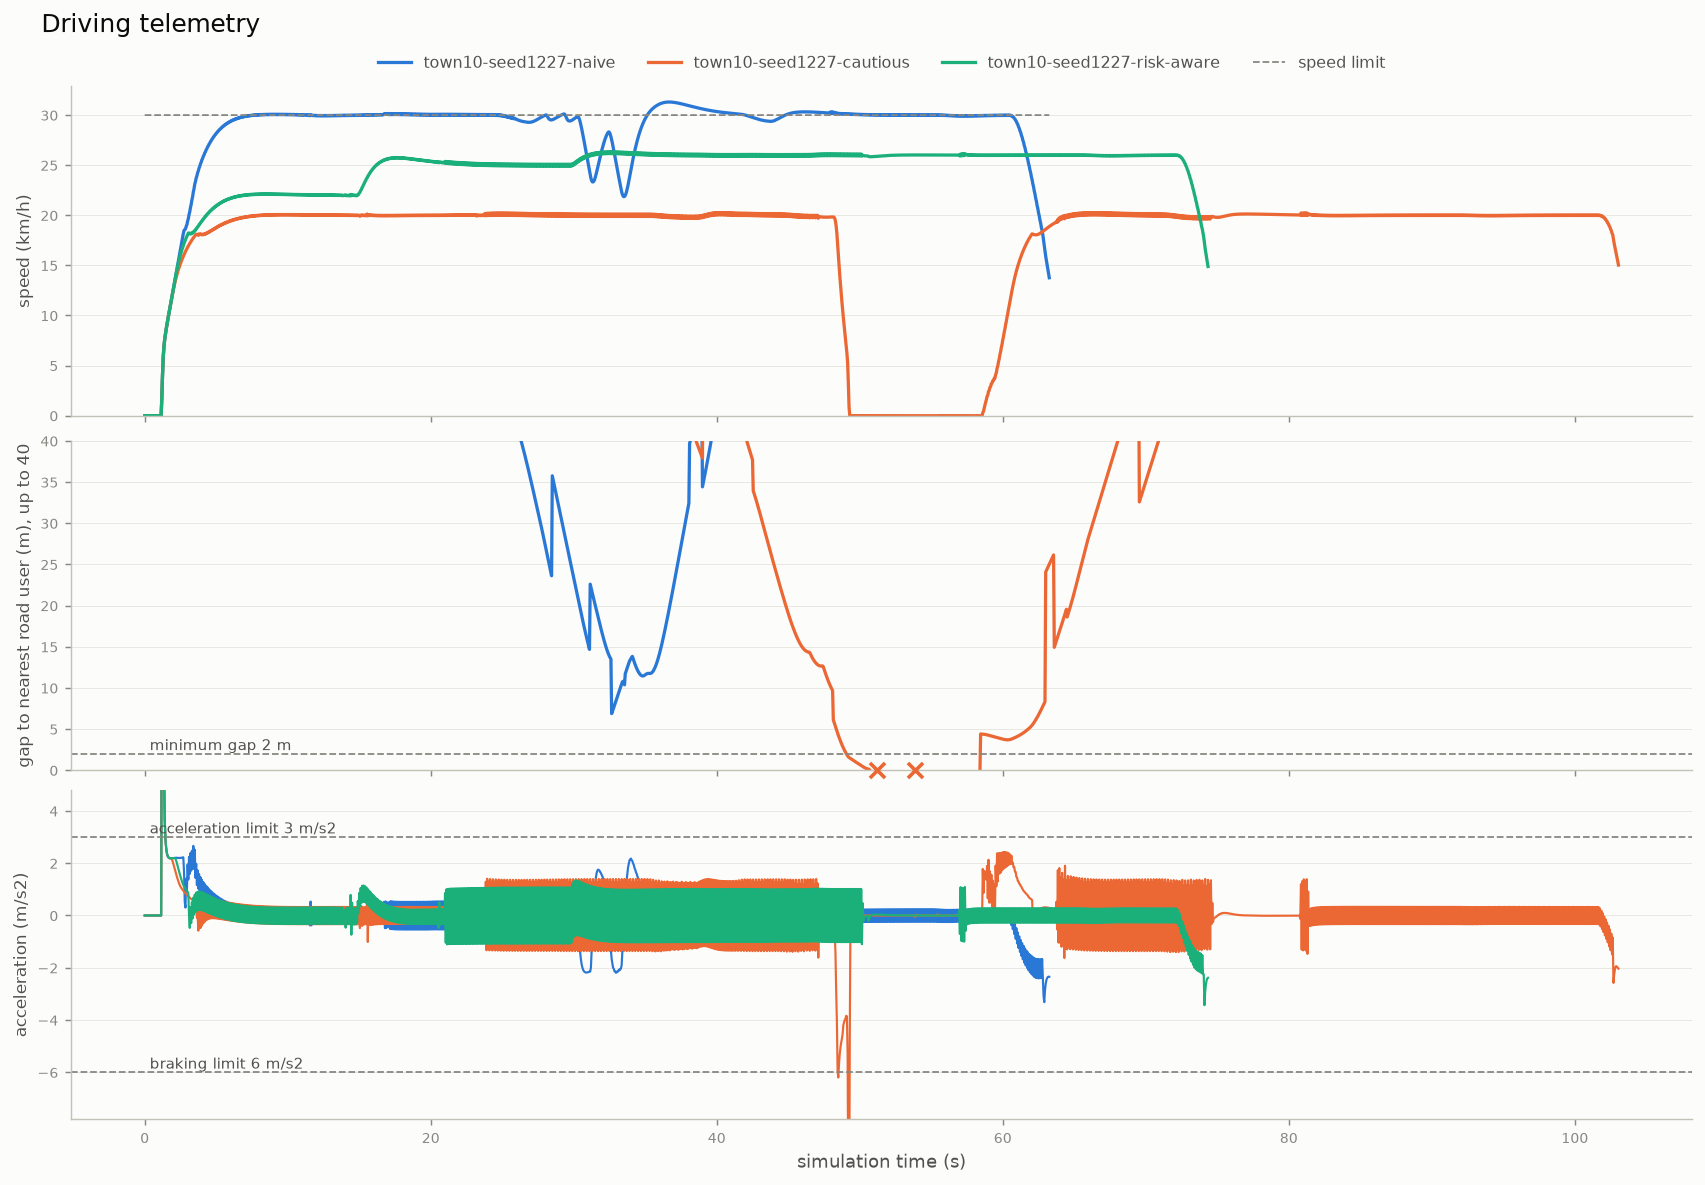

In [7]:
if runs:
    figure = Visualize.telemetry(runs.values())
    figure.savefig(OUTPUT / "town10-telemetry.png", bbox_inches="tight")

## Evaluate

Each safety requirement is a signal temporal logic (STL) formula of the form `always (condition)`. Its **margin** is the formula's robustness, in the signal's own unit: positive is how much room was left at the closest moment, and negative is how far past the limit the run went. The percentage divides the margin by the limit, so requirements in different units can be compared.

The two acceleration limits count as breached only when exceeded for half a second without a break, because acceleration is measured tick to tick and a single tick can spike.

In [8]:
evaluations = {mode: Driver.evaluate(run) for mode, run in runs.items()}
for evaluation in evaluations.values():
    print(evaluation.summary())
    print()

town10-seed1227-naive: arrived, 63.3 s, 496 m, 0 collisions, all requirements kept
  no_collision    sat   margin    +0.50        (  +100%) worst at    0.0 s   always (collision <= 0.5)
  min_gap         sat   margin    +4.88 m      (  +244%) worst at   32.7 s   always (gap_m >= 2)
  braking         sat   margin    +3.66 m/s2   (   +61%) worst at   63.3 s   always (eventually[0,0.5] (acceleration_mps2 >= -6))
  acceleration    sat   margin    +0.77 m/s2   (   +26%) worst at    1.2 s   always (eventually[0,0.5] (acceleration_mps2 <= 3))
  speed_limit     sat   margin    +0.47 m/s    (   +47%) worst at   36.7 s   always (speed_mps <= (speed_limit_mps + 0.833333))

town10-seed1227-cautious: arrived, 103.1 s, 496 m, 2 collisions, BREACHED
  no_collision    unsat margin    -0.50        (  -100%) worst at   51.2 s   always (collision <= 0.5)
  min_gap         unsat margin    -2.40 m      (  -120%) worst at   51.3 s   always (gap_m >= 2)
  braking         sat   margin    +1.92 m/s2   (   +32%

The requirement closest to its limit is the near miss to look at, whether or not anything was breached.

In [9]:
for mode, evaluation in evaluations.items():
    closest = evaluation.closest
    print(f"{mode:11} {'kept all' if evaluation.satisfied else 'breached':9} closest: {closest.name}, margin {closest.robustness:+.2f} {closest.unit} "
          f"at {closest.worst_time_s:.1f} s")

naive       kept all  closest: acceleration, margin +0.77 m/s2 at 1.2 s
cautious    breached  closest: min_gap, margin -2.40 m at 51.3 s
risk-aware  kept all  closest: acceleration, margin +0.77 m/s2 at 1.2 s


The same telemetry can be checked against other requirements, without driving again.

In [10]:
strict = DrivingSafetyReq(min_gap_m=6.0, max_deceleration_mps2=3.0)
for mode, run in runs.items():
    result = Driver.evaluate(run, strict)
    print(f"{mode:11} breached under the stricter limits: {[r.name for r in result.breached] or 'nothing'}")

naive       breached under the stricter limits: nothing
cautious    breached under the stricter limits: ['no_collision', 'min_gap', 'braking']
risk-aware  breached under the stricter limits: nothing
